# Exp27 — Experiment A: does word-order state transfer across languages? (gate, ceiling, donor breadth)

**Question.** Exp26 could not tell "no cross-language transfer of word-order state" from "broken instrument". This notebook fixes the three instrument problems *before* any claim is made:

| Exp26 problem | Fix here |
|---|---|
| No scale: `frac_flip` had no ceiling | **A1** same-language anti-order ceiling (German main/V2 clause ↔ subordinate verb-final clause, same verbs/objects) |
| HI was the only SOV / postpositional donor | **A2** Gemma has JA, KO, TR, HI (4 head-last donors), gated per language |
| Adjective decision token preceded all content; candidate choice confounded with "is an adjective present at all" | **A3** both candidates contain the same words in opposite order (`verb obj` vs `obj verb`; `noun adj` vs `adj noun`), numeral frame ("There are two/three/four/five …", numeral cycles over scenes so the floor is non-degenerate) |

**Measurement.** Residual patching at the last prefix token, one layer at a time, donor state → recipient prompt. Order score `S = logP(head-first string) − logP(head-last string)`.
Per item: `shift_toward = native margin lost after patching`, `flip = native order no longer preferred`.
`DTI = metric(opposite-order foreign donor) − metric(same-order foreign donor)`; floor = same language, different scene.
Two constructions on independent typological axes: **clause** (VO vs OV) and **adjective** (N-Adj vs Adj-N). Head-first: clause EN/FR/ES/DE; adj FR/ES. Head-last: clause HI/JA/KO/TR; adj EN/DE/HI/JA/KO/TR.

**Pre-registered decision rule** (frozen to `exp27_results/prereg.json` on first run, edit-protected):
1. Language-construction cell is usable only if clean native-order accuracy ≥ 0.75 on ≥ 8 items.
2. **Ceiling gate:** German in-language DTI (flip, late window) mean ≥ 0.30 and each direction ≥ 0.15. If it fails, the instrument cannot see transfer even when it must exist → *no cross-language claim is allowed*.
3. A recipient cell is **clean** only with ≥ 2 usable opposite-order donors, ≥ 1 same-order donor, ≥ 8 scenes.
4. Clean cell is **WALL** if DTI ≤ 0.05; **TRANSFER** if DTI ≥ 0.15 *and* still ≥ 0.15 after dropping any single opposite-order donor (kills single-donor artifacts); otherwise AMBIGUOUS.
5. Any TRANSFER cell → inversion framing abandoned. ≥ 4 WALL cells spanning both constructions and no TRANSFER → word-order leg of the inversion supported. Anything else → inconclusive.

**What a WALL does and does not mean.** It means last-token residual patching at layers ≥ 50% depth does not move the order preference across languages, while the same instrument does move it within German. It does *not* prove the model has no shared order machinery (see B4-style probes and attention-level patching for that).

**Run order:** cells 1 → end. Re-run the whole notebook with `MODEL_KEY` = `gemma-2-2b` / `gemma-2-27b-it` for A4 (scale). Results are cached per model.

**VERIFY before any claim:** all hand-written HI/JA/KO/TR items (esp. HI "मरीज़ की मदद करता है", TR "sağlam" for *stable*, KO "인기 있는", JA "人気の") need a native read. Items that fail tokenization or the clean gate are dropped automatically and counted in the preflight table.

In [1]:
import os, json
# ============================ CONFIG ============================
GPU_ID       = 2
MODEL_KEY    = "gemma-2-9b"          # rerun with "gemma-2-2b" and "gemma-2-27b-it" for A4
MODEL_PATHS  = {
    "gemma-2-2b":     "google/gemma-2-2b",
    "gemma-2-9b":     "/home/models/gemma-2-9b",
    "gemma-2-9b-it":  "/home/models/gemma-2-9b-it",
    "gemma-2-27b-it": "/home/models/gemma-2-27b-it",
}
DTYPE          = "bfloat16"
RESULTS_DIR    = "exp27_results"
LAYER_STRIDE   = 2        # layers patched = every LAYER_STRIDE-th + last
LATE_FRAC      = 0.5      # "late window" = layers >= LATE_FRAC * n_layers  (same rule as Exp26)
N_FLOOR_SCENES = 3        # same-language different-scene donors per recipient
BATCH          = 96
N_BOOT         = 2000
SEED           = 0

# ---------------- PRE-REGISTERED DECISION RULE (frozen on first run) ----------------
PREREG = dict(
    gate_acc=0.75, gate_min_items=8,
    ceil_min=0.30, ceil_dir_min=0.15,
    wall_max=0.05, transfer_min=0.15,
    min_opp_donors=2, min_same_donors=1, min_scenes=8,
    min_wall_cells=4, min_wall_constructions=2,
    primary_metric="flip", window_frac=LATE_FRAC,
)
os.makedirs(RESULTS_DIR, exist_ok=True)
_p = f"{RESULTS_DIR}/prereg.json"
_payload = json.dumps(PREREG, sort_keys=True, indent=1)
if os.path.exists(_p):
    if open(_p).read() != _payload:
        raise RuntimeError("PREREG differs from the frozen file exp27_results/prereg.json. "
                           "Changing the decision rule after seeing results is exactly what this file prevents. "
                           "If this is a deliberate NEW study, use a new RESULTS_DIR.")
else:
    open(_p, "w").write(_payload)
print("prereg frozen:", PREREG)

prereg frozen: {'gate_acc': 0.75, 'gate_min_items': 8, 'ceil_min': 0.3, 'ceil_dir_min': 0.15, 'wall_max': 0.05, 'transfer_min': 0.15, 'min_opp_donors': 2, 'min_same_donors': 1, 'min_scenes': 8, 'min_wall_cells': 4, 'min_wall_constructions': 2, 'primary_metric': 'flip', 'window_frac': 0.5}


In [2]:
import time, math, random, glob
os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU_ID)      # must precede the first CUDA call
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
RNG = np.random.default_rng(SEED)
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

torch 2.11.0+cu130 | cuda: True


In [3]:
# ============================ ITEM BANKS ============================
# Every scene is the same meaning in all 8 languages. All non-EN/FR/ES/DE items: VERIFY with a native speaker.
LANGS = ["en", "fr", "es", "de", "hi", "ja", "ko", "tr"]
NOSPACE = {"ja"}
SCRIPT = {"en":"latin","fr":"latin","es":"latin","de":"latin","tr":"latin","hi":"deva","ja":"jpan","ko":"hang"}
CLAUSE_ORDER = {"en":"first","fr":"first","es":"first","de":"first","hi":"last","ja":"last","ko":"last","tr":"last"}  # verb before object?
ADJ_ORDER    = {"fr":"first","es":"first","en":"last","de":"last","hi":"last","ja":"last","ko":"last","tr":"last"}  # noun before adjective?

# (subject, verb, object); prefix = subject, the model must continue with verb+object in some order
CLAUSE = {
 "en": [("The girl","reads","a book"),("The boy","eats","an apple"),("The woman","drinks","the tea"),("The man","opens","the door"),
        ("The child","draws","a picture"),("The teacher","writes","a letter"),("The dog","sees","the cat"),("The farmer","buys","bread"),
        ("The cook","makes","soup"),("The driver","repairs","the car"),("The sister","sings","a song"),("The doctor","helps","the patient")],
 "fr": [("La fille","lit","un livre"),("Le garçon","mange","une pomme"),("La femme","boit","le thé"),("L'homme","ouvre","la porte"),
        ("L'enfant","dessine","un dessin"),("Le professeur","écrit","une lettre"),("Le chien","voit","le chat"),("Le fermier","achète","du pain"),
        ("Le cuisinier","prépare","la soupe"),("Le chauffeur","répare","la voiture"),("La sœur","chante","une chanson"),("Le médecin","aide","le patient")],
 "es": [("La chica","lee","un libro"),("El chico","come","una manzana"),("La mujer","bebe","el té"),("El hombre","abre","la puerta"),
        ("El niño","dibuja","un dibujo"),("El profesor","escribe","una carta"),("El perro","ve","al gato"),("El granjero","compra","pan"),
        ("El cocinero","prepara","la sopa"),("El conductor","repara","el coche"),("La hermana","canta","una canción"),("El médico","ayuda","al paciente")],
 "de": [("Das Mädchen","liest","ein Buch"),("Der Junge","isst","einen Apfel"),("Die Frau","trinkt","den Tee"),("Der Mann","öffnet","die Tür"),
        ("Das Kind","zeichnet","ein Bild"),("Der Lehrer","schreibt","einen Brief"),("Der Hund","sieht","die Katze"),("Der Bauer","kauft","Brot"),
        ("Der Koch","kocht","die Suppe"),("Der Fahrer","repariert","das Auto"),("Die Schwester","singt","ein Lied"),("Der Arzt","hilft","dem Patienten")],
 "hi": [("लड़की","पढ़ती है","एक किताब"),("लड़का","खाता है","एक सेब"),("औरत","पीती है","चाय"),("आदमी","खोलता है","दरवाज़ा"),
        ("बच्चा","बनाता है","एक चित्र"),("अध्यापक","लिखता है","एक पत्र"),("कुत्ता","देखता है","बिल्ली को"),("किसान","खरीदता है","रोटी"),
        ("रसोइया","बनाता है","सूप"),("ड्राइवर","ठीक करता है","कार"),("बहन","गाती है","एक गाना"),("डॉक्टर","करता है","मरीज़ की मदद")],
 "ja": [("女の子が","読む","本を"),("男の子が","食べる","りんごを"),("女性が","飲む","お茶を"),("男性が","開ける","ドアを"),
        ("子供が","描く","絵を"),("先生が","書く","手紙を"),("犬が","見る","猫を"),("農夫が","買う","パンを"),
        ("料理人が","作る","スープを"),("運転手が","直す","車を"),("姉が","歌う","歌を"),("医者が","助ける","患者を")],
 "ko": [("소녀가","읽는다","책을"),("소년이","먹는다","사과를"),("여자가","마신다","차를"),("남자가","연다","문을"),
        ("아이가","그린다","그림을"),("선생님이","쓴다","편지를"),("개가","본다","고양이를"),("농부가","산다","빵을"),
        ("요리사가","만든다","수프를"),("운전사가","고친다","차를"),("여동생이","부른다","노래를"),("의사가","돕는다","환자를")],
 "tr": [("Kız","okur","bir kitap"),("Oğlan","yer","bir elma"),("Kadın","içer","çayı"),("Adam","açar","kapıyı"),
        ("Çocuk","çizer","bir resim"),("Öğretmen","yazar","bir mektup"),("Köpek","görür","kediyi"),("Çiftçi","alır","ekmek"),
        ("Aşçı","yapar","çorba"),("Şoför","tamir eder","arabayı"),("Kız kardeş","söyler","bir şarkı"),("Doktor","yardım eder","hastaya")],
}

# numeral-frame NP; prefix ends at the numeral/counter, so no article-gender leak. (noun, adjective); plural-invariant adjectives chosen for FR/ES.
# The numeral cycles over scenes (2,3,4,5) so that the same-language "floor" donor carries a DIFFERENT state of the same order.
# (With one fixed prefix per language the floor patch would be a self-patch: exactly 0 by construction.)
STEM = {"en":"There are","fr":"Il y a","es":"Hay","de":"Es gibt","hi":"वहाँ","ja":"そこには","ko":"거기에","tr":"Orada"}
NUMS = {"en":["two","three","four","five"], "fr":["deux","trois","quatre","cinq"], "es":["dos","tres","cuatro","cinco"],
        "de":["zwei","drei","vier","fünf"], "hi":["दो","तीन","चार","पाँच"], "ja":["二つの","三つの","四つの","五つの"],
        "ko":["두 개의","세 개의","네 개의","다섯 개의"], "tr":["iki","üç","dört","beş"]}
ADJ = {"en":"There are two","fr":"Il y a deux","es":"Hay dos","de":"Es gibt zwei",
           "hi":"वहाँ दो","ja":"そこには二つの","ko":"거기에 두 개의","tr":"Orada iki"}
ADJ = {
 "en": [("exercises","easy"),("tools","useful"),("songs","popular"),("vases","fragile"),("solutions","possible"),
        ("bridges","stable"),("rules","flexible"),("workers","capable"),("questions","easy"),("books","useful")],
 "fr": [("exercices","faciles"),("outils","utiles"),("chansons","populaires"),("vases","fragiles"),("solutions","possibles"),
        ("ponts","stables"),("règles","flexibles"),("ouvriers","capables"),("questions","faciles"),("livres","utiles")],
 "es": [("ejercicios","fáciles"),("herramientas","útiles"),("canciones","populares"),("jarrones","frágiles"),("soluciones","posibles"),
        ("puentes","estables"),("reglas","flexibles"),("obreros","capaces"),("preguntas","fáciles"),("libros","útiles")],
 "de": [("Übungen","einfache"),("Werkzeuge","nützliche"),("Lieder","beliebte"),("Vasen","zerbrechliche"),("Lösungen","mögliche"),
        ("Brücken","stabile"),("Regeln","flexible"),("Arbeiter","fähige"),("Fragen","einfache"),("Bücher","nützliche")],
 "hi": [("अभ्यास","आसान"),("उपकरण","उपयोगी"),("गाने","लोकप्रिय"),("फूलदान","नाज़ुक"),("समाधान","संभव"),
        ("पुल","स्थिर"),("नियम","लचीले"),("कर्मचारी","सक्षम"),("सवाल","आसान"),("किताबें","उपयोगी")],
 "ja": [("練習","簡単な"),("道具","便利な"),("歌","人気の"),("花瓶","壊れやすい"),("解決策","可能な"),
        ("橋","安定した"),("ルール","柔軟な"),("労働者","有能な"),("質問","簡単な"),("本","役に立つ")],
 "ko": [("연습","쉬운"),("도구","유용한"),("노래","인기 있는"),("꽃병","깨지기 쉬운"),("해결책","가능한"),
        ("다리","안정적인"),("규칙","유연한"),("일꾼","유능한"),("질문","쉬운"),("책","유용한")],
 "tr": [("alıştırma","kolay"),("alet","faydalı"),("şarkı","popüler"),("vazo","kırılgan"),("çözüm","mümkün"),
        ("köprü","sağlam"),("kural","esnek"),("işçi","yetenekli"),("soru","kolay"),("kitap","faydalı")],
}

# A1 ceiling: SAME language, SAME scenes, opposite order, only the frame differs.
#   V2 main-clause-like frames (verb right after subject)  vs  dass-clauses (verb-final)
DE_FRAMES = {"V2a":("Ich glaube, {S}","first"), "V2b":("Ich denke, {S}","first"),
             "SUBa":("Ich glaube, dass {S}","last"), "SUBb":("Ich denke, dass {S}","last")}

for l in LANGS:
    assert len(CLAUSE[l]) == 12 and len(ADJ[l]) == 10, l
def lower_first(s): return s[0].lower() + s[1:]

UNITS = []
def add_unit(**kw):
    kw["uid"] = len(UNITS); UNITS.append(kw)
for l in LANGS:
    sep = "" if l in NOSPACE else " "
    for s, (subj, verb, obj) in enumerate(CLAUSE[l]):
        add_unit(constr="clause", lang=l, scene=s, prefix=subj, hf=verb+sep+obj, hl=obj+sep+verb, native=CLAUSE_ORDER[l], sep=sep)
    for s, (noun, adj) in enumerate(ADJ[l]):
        add_unit(constr="adj", lang=l, scene=s, prefix=STEM[l]+sep+NUMS[l][s % 4], hf=noun+sep+adj, hl=adj+sep+noun, native=ADJ_ORDER[l], sep=sep)
for name, (frame, native) in DE_FRAMES.items():
    SCRIPT[name] = "latin"
    for s, (subj, verb, obj) in enumerate(CLAUSE["de"]):
        add_unit(constr="de_frames", lang=name, scene=s, prefix=frame.format(S=lower_first(subj)),
                 hf=verb+" "+obj, hl=obj+" "+verb, native=native, sep=" ")
for u in UNITS:
    u["sign"] = 1 if u["native"] == "first" else -1      # sign of S expected for the native order
print(len(UNITS), "units;", {c: sum(1 for u in UNITS if u["constr"]==c) for c in ("clause","adj","de_frames")})
print("example:", UNITS[0]["prefix"], "|", UNITS[0]["hf"], "|", UNITS[0]["hl"])

224 units; {'clause': 96, 'adj': 80, 'de_frames': 48}
example: The girl | reads a book | a book reads


In [4]:
# ============================ MODEL + CORE MACHINERY ============================
from transformers import AutoTokenizer, AutoModelForCausalLM
if "model" not in globals():                      # (skip if already loaded in this kernel)
    _path = MODEL_PATHS[MODEL_KEY]
    tok = AutoTokenizer.from_pretrained(_path)
    _kw = dict(torch_dtype=getattr(torch, DTYPE), device_map={"": 0})
    if "gemma" in MODEL_KEY: _kw["attn_implementation"] = "eager"
    model = AutoModelForCausalLM.from_pretrained(_path, **_kw)
    model.eval()

def get_layers(m):
    for path in ("model.layers", "transformer.h", "gpt_neox.layers"):
        obj = m
        try:
            for a in path.split("."): obj = getattr(obj, a)
            return list(obj)
        except AttributeError:
            continue
    raise RuntimeError("cannot find decoder layers")

LAYERS = get_layers(model); NL = len(LAYERS)
DEVM = next(model.parameters()).device
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else (tok.eos_token_id or 0)
LAYER_LIST = sorted(set(list(range(0, NL, LAYER_STRIDE)) + [NL-1]))
LATE0 = int(NL * LATE_FRAC)
print(f"{MODEL_KEY}: {NL} layers | patching layers {LAYER_LIST} | late window = layers >= {LATE0}")

def collate(id_lists):
    T = max(len(x) for x in id_lists)
    ids  = torch.full((len(id_lists), T), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(id_lists), T), dtype=torch.long)
    for i, x in enumerate(id_lists):
        ids[i, :len(x)] = torch.tensor(x); mask[i, :len(x)] = 1
    pos = torch.tensor([len(x) - 1 for x in id_lists], dtype=torch.long)
    return ids.to(DEVM), mask.to(DEVM), pos.to(DEVM)

def make_patch_hook(pos, vecs):
    def hook(mod, inp, out):
        h = out[0] if isinstance(out, tuple) else out
        h2 = h.clone()
        h2[torch.arange(h2.shape[0], device=h2.device), pos.to(h2.device)] = vecs.to(device=h2.device, dtype=h2.dtype)
        return (h2,) + tuple(out[1:]) if isinstance(out, tuple) else h2
    return hook

# ---- tokenisation: candidate = tokens after the prefix; prefix tokens must be an exact prefix of the full tokenisation
def encode_unit(u):
    ids_p = tok(u["prefix"])["input_ids"]
    rows, ok = [], True
    for key in ("hf", "hl"):
        ids = tok(u["prefix"] + u["sep"] + u[key])["input_ids"]
        if len(ids) <= len(ids_p) or ids[:len(ids_p)] != ids_p: ok = False
        rows.append(dict(ids=ids, p=len(ids_p) - 1, n=len(ids) - len(ids_p)))
    u["ids_p"], u["rows"], u["ok"] = ids_p, rows, ok
for u in UNITS: encode_unit(u)

@torch.no_grad()
def score_rows(rows, layer=None, vecs=None):
    """sum log P(candidate tokens | prefix) for each row; optional residual patch at the decision position of `layer`."""
    out_lp = []
    for i in range(0, len(rows), BATCH):
        chunk = rows[i:i+BATCH]
        ids, mask, _ = collate([r["ids"] for r in chunk])
        pos = torch.tensor([r["p"] for r in chunk], dtype=torch.long, device=DEVM)
        hk = None
        if layer is not None:
            hk = LAYERS[layer].register_forward_hook(make_patch_hook(pos, vecs[i:i+BATCH]))
        try:
            lg = model(input_ids=ids, attention_mask=mask, use_cache=False).logits
        finally:
            if hk is not None: hk.remove()
        for b, r in enumerate(chunk):
            l = torch.log_softmax(lg[b, r["p"]: r["p"] + r["n"]].float(), -1)
            tgt = torch.tensor(r["ids"][r["p"] + 1: r["p"] + 1 + r["n"]], device=l.device)
            out_lp.append(l.gather(1, tgt[:, None]).sum().item())
    return np.array(out_lp)

@torch.no_grad()
def capture_states(units):
    """residual stream output of every decoder layer at the last prefix token -> [N, n_layers, d] float32 (cpu)"""
    res = []
    for i in range(0, len(units), BATCH):
        chunk = units[i:i+BATCH]
        ids, mask, pos = collate([u["ids_p"] for u in chunk])
        store, hs = {}, []
        for li, layer in enumerate(LAYERS):
            def mk(li):
                def hook(m, inp, out):
                    h = out[0] if isinstance(out, tuple) else out
                    store[li] = h[torch.arange(h.shape[0], device=h.device), pos.to(h.device)].float().cpu()
                return hook
            hs.append(layer.register_forward_hook(mk(li)))
        try:
            model(input_ids=ids, attention_mask=mask, use_cache=False)
        finally:
            for h in hs: h.remove()
        res.append(torch.stack([store[li] for li in range(NL)], 1))
    return torch.cat(res)

@torch.no_grad()
def logp_at_decision(prefix_ids, layer=None, vecs=None):
    ids, mask, pos = collate(prefix_ids)
    hk = LAYERS[layer].register_forward_hook(make_patch_hook(pos, vecs)) if layer is not None else None
    try:
        lg = model(input_ids=ids, attention_mask=mask, use_cache=False).logits
    finally:
        if hk is not None: hk.remove()
    return torch.log_softmax(lg[torch.arange(len(prefix_ids)), pos].float(), -1).cpu()

n_bad = sum(1 for u in UNITS if not u["ok"])
print(f"tokenisation check: {n_bad}/{len(UNITS)} units fail the prefix-consistency test (dropped automatically)")

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 464/464 [00:01<00:00, 262.08it/s]


gemma-2-9b: 42 layers | patching layers [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 41] | late window = layers >= 21
tokenisation check: 5/224 units fail the prefix-consistency test (dropped automatically)


In [5]:
# ============================ SELF-TESTS (must pass before anything is interpreted) ============================
STATES = capture_states(UNITS)                       # [N_units, NL, d]
print("captured states", tuple(STATES.shape))

def _units(constr, lang, k=12):
    return [u for u in UNITS if u["constr"] == constr and u["lang"] == lang and u["ok"]][:k]

# (1) self-patch: patching a prompt with its OWN state must leave the order score unchanged
us = _units("clause", "en") or _units("clause", "fr")
rows = [r for u in us for r in u["rows"]]
S0 = score_rows(rows)
worst = 0.0
for L in (LAYER_LIST[len(LAYER_LIST)//2], LAYER_LIST[-1]):
    vecs = torch.stack([STATES[u["uid"], L] for u in us for _ in (0, 1)])
    Sp = score_rows(rows, L, vecs)
    worst = max(worst, float(np.abs(Sp - S0).max()))
print(f"[1] self-patch max |delta logP| = {worst:.4f}")
assert worst < 0.25, "hook is broken: self-patch changes the score"

# (2) overwrite: patching the LAST layer's output at the decision token must reproduce the donor's next-token distribution there
rec = _units("clause", "en", 8) or us
don = [next(x for x in UNITS if x["constr"] == "clause" and x["lang"] == ("ja" if "ja" in LANGS else "fr") and x["scene"] == u["scene"]) for u in rec]
LP_don = logp_at_decision([d["ids_p"] for d in don])
LP_pat = logp_at_decision([u["ids_p"] for u in rec], NL - 1, torch.stack([STATES[d["uid"], NL - 1] for d in don]))
dmax = float((LP_don - LP_pat).abs().max())
print(f"[2] last-layer overwrite max |delta log-prob| over the full vocabulary = {dmax:.4f}")
assert dmax < 1.0, "patch is not landing on the decision position"

# (3) the patch must be able to change things at all (mid-depth)
Lmid = LAYER_LIST[len(LAYER_LIST)//2]
Sx = score_rows([r for u in rec for r in u["rows"]], Lmid, torch.stack([STATES[d["uid"], Lmid] for d in don for _ in (0, 1)]))
S00 = score_rows([r for u in rec for r in u["rows"]])
print(f"[3] mean |S change| when patching another language's state at layer {Lmid}: {np.abs(Sx - S00).mean():.3f} nats (informational)")
print("SELF-TESTS PASSED")

captured states (224, 42, 3584)
[1] self-patch max |delta logP| = 0.2369
[2] last-layer overwrite max |delta log-prob| over the full vocabulary = 0.7639
[3] mean |S change| when patching another language's state at layer 22: 14.960 nats (informational)
SELF-TESTS PASSED


In [6]:
# ============================ A2 PREFLIGHT GATE: does each language know its own order at the decision token? ============================
okU = [u for u in UNITS if u["ok"]]
S_all = score_rows([r for u in okU for r in u["rows"]])
for k, u in enumerate(okU):
    u["S0"] = float(S_all[2*k] - S_all[2*k + 1])         # logP(head-first) - logP(head-last)
    u["margin"] = u["S0"] * u["sign"]                    # >0 means native order preferred
    u["clean_ok"] = u["margin"] > 0
for u in UNITS:
    if not u["ok"]: u["S0"], u["margin"], u["clean_ok"] = np.nan, np.nan, False

gate_rows, PASS = [], {}
for c in ("clause", "adj", "de_frames"):
    for l in sorted({u["lang"] for u in UNITS if u["constr"] == c}):
        us = [u for u in UNITS if u["constr"] == c and u["lang"] == l]
        okc = [u for u in us if u["ok"]]
        acc = float(np.mean([u["clean_ok"] for u in okc])) if okc else float("nan")
        PASS[(c, l)] = (len(okc) >= PREREG["gate_min_items"]) and (acc >= PREREG["gate_acc"])
        gate_rows.append(dict(constr=c, lang=l, native=us[0]["native"], n_items=len(us), n_tok_ok=len(okc),
                              clean_acc=round(acc, 2), mean_margin=round(float(np.nanmean([u["margin"] for u in okc])), 2) if okc else np.nan,
                              PASS=PASS[(c, l)]))
GATE = pd.DataFrame(gate_rows)
print(GATE.to_string(index=False))
GATE.to_csv(f"{RESULTS_DIR}/{MODEL_KEY}_preflight_gate.csv", index=False)
for c in ("clause", "adj"):
    ho = [r["lang"] for r in gate_rows if r["constr"] == c and r["PASS"] and r["native"] == "last"]
    print(f"{c}: usable head-last donors = {ho} | need >= {PREREG['min_opp_donors']} for head-first recipients")

   constr lang native  n_items  n_tok_ok  clean_acc  mean_margin  PASS
   clause   de  first       12        12       1.00         7.59  True
   clause   en  first       12        12       1.00        10.55  True
   clause   es  first       12        12       1.00        11.29  True
   clause   fr  first       12        12       1.00        11.42  True
   clause   hi   last       12        12       0.92         4.70  True
   clause   ja   last       12         8       0.88         3.30  True
   clause   ko   last       12        12       1.00         9.06  True
   clause   tr   last       12        12       1.00         6.42  True
      adj   de   last       10        10       1.00        10.84  True
      adj   en   last       10        10       0.90         4.82  True
      adj   es  first       10        10       0.90         6.13  True
      adj   fr  first       10        10       1.00        10.38  True
      adj   hi   last       10        10       1.00         2.57  True
      

In [7]:
# ============================ CORE PATCHING RUN ============================
def donor_pairs(constr):
    by = {(u["lang"], u["scene"]): u for u in UNITS if u["constr"] == constr}
    langs = sorted({u["lang"] for u in UNITS if u["constr"] == constr})
    nsc = max(u["scene"] for u in UNITS if u["constr"] == constr) + 1
    pairs = []
    for r in UNITS:
        if r["constr"] != constr or not PASS.get((constr, r["lang"]), False) or not r["ok"] or not r["clean_ok"]: continue
        for dl in langs:
            if dl == r["lang"] or not PASS.get((constr, dl), False): continue
            d = by[(dl, r["scene"])]
            if not d["ok"] or not d["clean_ok"]: continue          # donor must itself show its native order on this scene
            pairs.append((r["uid"], d["uid"], "same" if d["native"] == r["native"] else "opp", dl))
        for k in range(1, N_FLOOR_SCENES + 1):                       # floor: same language/frame, different scene
            d = by[(r["lang"], (r["scene"] + k) % nsc)]
            if d["ok"] and d["clean_ok"]:
                pairs.append((r["uid"], d["uid"], "floor", r["lang"]))
    return pairs

def run_patching(constr):
    path = f"{RESULTS_DIR}/{MODEL_KEY}_{constr}.csv"
    if os.path.exists(path):
        print("cached:", path); return pd.read_csv(path)
    pairs = donor_pairs(constr)
    print(f"{constr}: {len(pairs)} (recipient, donor) pairs x {len(LAYER_LIST)} layers")
    recs = []
    t0 = time.time()
    for L in LAYER_LIST:
        rows, vecs = [], []
        for (ri, di, kind, dl) in pairs:
            r = UNITS[ri]
            rows += r["rows"]; vecs += [STATES[di, L], STATES[di, L]]
        lp = score_rows(rows, L, torch.stack(vecs))
        for k, (ri, di, kind, dl) in enumerate(pairs):
            r = UNITS[ri]
            recs.append(dict(constr=constr, recip=r["lang"], scene=r["scene"], donor=dl, kind=kind, layer=L,
                             S_clean=r["S0"], S_patched=float(lp[2*k] - lp[2*k + 1]), sign=r["sign"]))
        print(f"  layer {L:3d} done ({time.time()-t0:.0f}s)", end="\r")
    df = pd.DataFrame(recs)
    df["shift_toward"] = -df["sign"] * (df["S_patched"] - df["S_clean"])     # native margin lost (nats); >0 = toward the other order
    df["flip"] = ((df["S_patched"] * df["sign"]) < 0).astype(float)           # native order no longer preferred
    df.to_csv(path, index=False)
    return df

DF = {c: run_patching(c) for c in ("de_frames", "clause", "adj")}
for c, d in DF.items(): print(c, d.shape)

de_frames: 266 (recipient, donor) pairs x 22 layers
clause: 847 (recipient, donor) pairs x 22 layers
adj: 740 (recipient, donor) pairs x 22 layers
de_frames (5852, 11)s)
clause (18634, 11)
adj (16280, 11)


In [8]:
# ============================ ANALYSIS: DTI per recipient, bootstrap over scenes, donor-robustness ============================
def window_table(df):
    d = df[df.layer >= LATE0]
    return d.groupby(["recip", "scene", "kind", "donor"], as_index=False)[["shift_toward", "flip"]].mean()

def scene_dti(W, recips, metric, opp=None, same=None):
    w = W[W.recip.isin(recips)]
    if opp  is not None: w = w[(w.kind != "opp")  | w.donor.isin(opp)]
    if same is not None: w = w[(w.kind != "same") | w.donor.isin(same)]
    per = w.groupby(["recip", "scene", "kind"])[metric].mean().unstack("kind")
    if "opp" not in per.columns or "same" not in per.columns: return np.array([])
    per["dti"] = per["opp"] - per["same"]
    return per["dti"].groupby("scene").mean().dropna().values

def boot(x, nb=N_BOOT):
    x = np.asarray(x, float)
    if len(x) == 0: return (np.nan, np.nan, np.nan)
    idx = RNG.integers(0, len(x), (nb, len(x)))
    bm = x[idx].mean(1)
    return float(x.mean()), float(np.percentile(bm, 2.5)), float(np.percentile(bm, 97.5))

LATIN = {l for l, s in SCRIPT.items() if s == "latin"}

def cell_report(W, constr, recip):
    wr = W[W.recip == recip]
    opp, same = sorted(wr[wr.kind == "opp"].donor.unique()), sorted(wr[wr.kind == "same"].donor.unique())
    out = dict(constr=constr, recip=recip, n_opp=len(opp), n_same=len(same), opp=",".join(opp), same=",".join(same))
    x = scene_dti(W, [recip], "flip");          out["n_scenes"] = len(x)
    out["dti_flip"], out["lo"], out["hi"] = boot(x)
    out["dti_shift"], out["shift_lo"], out["shift_hi"] = boot(scene_dti(W, [recip], "shift_toward"))
    for k in ("opp", "same", "floor"):
        v = wr[wr.kind == k]
        out[f"{k}_flip"] = float(v.flip.mean()) if len(v) else np.nan
        out[f"{k}_shift"] = float(v.shift_toward.mean()) if len(v) else np.nan
    loo = {d: float(np.mean(scene_dti(W, [recip], "flip", opp=[o for o in opp if o != d]))) if len(opp) > 1 and len(scene_dti(W, [recip], "flip", opp=[o for o in opp if o != d])) else np.nan for d in opp}
    out["loo_min"] = float(np.nanmin(list(loo.values()))) if loo and not all(np.isnan(list(loo.values()))) else np.nan
    out["loo_worst_drop"] = min(loo, key=lambda k: loo[k]) if loo and not all(np.isnan(list(loo.values()))) else ""
    xl = scene_dti(W, [recip], "flip", opp=[o for o in opp if o in LATIN], same=[s for s in same if s in LATIN])
    out["dti_latin_only"] = float(np.mean(xl)) if len(xl) else np.nan
    return out

def classify(r):
    P = PREREG
    if not (r["n_opp"] >= P["min_opp_donors"] and r["n_same"] >= P["min_same_donors"] and r["n_scenes"] >= P["min_scenes"]):
        return "UNUSABLE"
    if r["dti_flip"] >= P["transfer_min"] and r["loo_min"] >= P["transfer_min"]: return "TRANSFER"
    if r["dti_flip"] <= P["wall_max"]: return "WALL"
    return "AMBIGUOUS"

WT = {c: window_table(DF[c]) for c in DF}

# ---- A1: in-language ceiling (German frames) ----
CEIL = None
Wf = WT["de_frames"]
dirs = {"V2<-SUB (native VO, donor OV)": ["V2a", "V2b"], "SUB<-V2 (native OV, donor VO)": ["SUBa", "SUBb"]}
ceil_rows = []
for name, rc in dirs.items():
    if not all(PASS.get(("de_frames", r), False) for r in rc):
        ceil_rows.append(dict(direction=name, dti_flip=np.nan, lo=np.nan, hi=np.nan, dti_shift=np.nan, n_scenes=0)); continue
    xf, xs = scene_dti(Wf, rc, "flip"), scene_dti(Wf, rc, "shift_toward")
    f, flo, fhi = boot(xf); s, _, _ = boot(xs)
    ceil_rows.append(dict(direction=name, dti_flip=f, lo=flo, hi=fhi, dti_shift=s, n_scenes=len(xf)))
CEILDF = pd.DataFrame(ceil_rows)
print("=== A1 same-language ceiling (German, same scenes, only the frame/order differs) ===")
print(CEILDF.round(3).to_string(index=False))
if CEILDF.dti_flip.notna().all():
    CEIL = dict(flip=float(CEILDF.dti_flip.mean()), shift=float(CEILDF.dti_shift.mean()), min_dir=float(CEILDF.dti_flip.min()))
    CEIL["pass"] = (CEIL["flip"] >= PREREG["ceil_min"]) and (CEIL["min_dir"] >= PREREG["ceil_dir_min"])
    print(f"ceiling flip={CEIL['flip']:.3f} shift={CEIL['shift']:.2f} nats | each direction >= {PREREG['ceil_dir_min']}? {CEIL['min_dir']>=PREREG['ceil_dir_min']} | GATE PASS = {CEIL['pass']}")
else:
    print("ceiling unavailable (German frames failed the clean gate) -> no cross-language claim allowed")

# ---- cross-language cells ----
REP = []
for c in ("clause", "adj"):
    for r in sorted(WT[c].recip.unique()):
        REP.append(cell_report(WT[c], c, r))
REPDF = pd.DataFrame(REP)
REPDF["class"] = REPDF.apply(classify, axis=1)
if CEIL: REPDF["shift_over_ceiling"] = REPDF.dti_shift / CEIL["shift"]
cols = ["constr","recip","n_opp","n_same","n_scenes","dti_flip","lo","hi","opp_flip","same_flip","floor_flip","dti_shift","floor_shift","loo_min","loo_worst_drop","dti_latin_only","class"]
print("\n=== cross-language DTI, late window (flip is primary) ===")
print(REPDF[cols].round(3).to_string(index=False))
REPDF.to_csv(f"{RESULTS_DIR}/{MODEL_KEY}_cell_report.csv", index=False)
for c in DF:
    fl = DF[c][(DF[c].kind == "floor") & (DF[c].layer >= LATE0)]
    if len(fl) and fl.shift_toward.std() == 0: print("WARNING degenerate floor in", c)

=== A1 same-language ceiling (German, same scenes, only the frame/order differs) ===
                    direction  dti_flip    lo    hi  dti_shift  n_scenes
V2<-SUB (native VO, donor OV)     0.738 0.579 0.847      8.562        11
SUB<-V2 (native OV, donor VO)     0.729 0.686 0.762      8.218        11
ceiling flip=0.733 shift=8.39 nats | each direction >= 0.15? True | GATE PASS = True

=== cross-language DTI, late window (flip is primary) ===
constr recip  n_opp  n_same  n_scenes  dti_flip     lo     hi  opp_flip  same_flip  floor_flip  dti_shift  floor_shift  loo_min loo_worst_drop  dti_latin_only     class
clause    de      4       3        12    -0.097 -0.319  0.107     0.227      0.336       0.083      0.046        0.675   -0.131             ko          -0.162      WALL
clause    en      4       3        12     0.001 -0.162  0.162     0.184      0.199       0.051     -0.585        0.715   -0.047             ko           0.088      WALL
clause    es      4       3        12    -0.0

In [9]:
# ============================ DONOR MATRICES: mean native-margin loss (nats), late window ============================
# A single donor column that dominates = the single-donor artifact that sank Exp26. Read these before trusting any DTI.
for c in ("clause", "adj"):
    W = WT[c]
    M = W[W.kind != "floor"].groupby(["recip", "donor"])["shift_toward"].mean().unstack("donor")
    M["FLOOR"] = W[W.kind == "floor"].groupby("recip")["shift_toward"].mean()
    print(f"\n--- {c}: rows = recipient, cols = donor language (margin lost, nats) ---")
    print(M.round(2).to_string())
    print("order classes:", {l: (CLAUSE_ORDER if c == "clause" else ADJ_ORDER)[l] for l in LANGS})


--- clause: rows = recipient, cols = donor language (margin lost, nats) ---
donor    de    en    es    fr    hi    ja    ko    tr  FLOOR
recip                                                       
de      NaN  0.32  2.55  2.00  3.29 -2.12  2.76  1.24   0.67
en     1.79   NaN  5.41  9.31  5.61 -2.39  6.68  7.42   0.72
es     2.80  7.10   NaN  2.71 -0.23  1.38  3.73  4.83   0.86
fr     5.17  5.40  4.50   NaN  0.73 -3.48  4.25  5.30   1.51
hi     3.99  1.78  2.86  3.36   NaN  2.74  0.63 -0.08  -0.54
ja    -1.36 -1.19  1.35  1.90  0.17   NaN -3.54 -0.28   1.56
ko     1.99  0.10  0.06  1.02 -0.55  1.68   NaN -0.64   0.27
tr    -1.82 -1.37  0.88  0.52 -0.31 -9.97  1.12   NaN  -1.07
order classes: {'en': 'first', 'fr': 'first', 'es': 'first', 'de': 'first', 'hi': 'last', 'ja': 'last', 'ko': 'last', 'tr': 'last'}

--- adj: rows = recipient, cols = donor language (margin lost, nats) ---
donor    de    en    es    fr    hi    ja    ko    tr  FLOOR
recip                                         

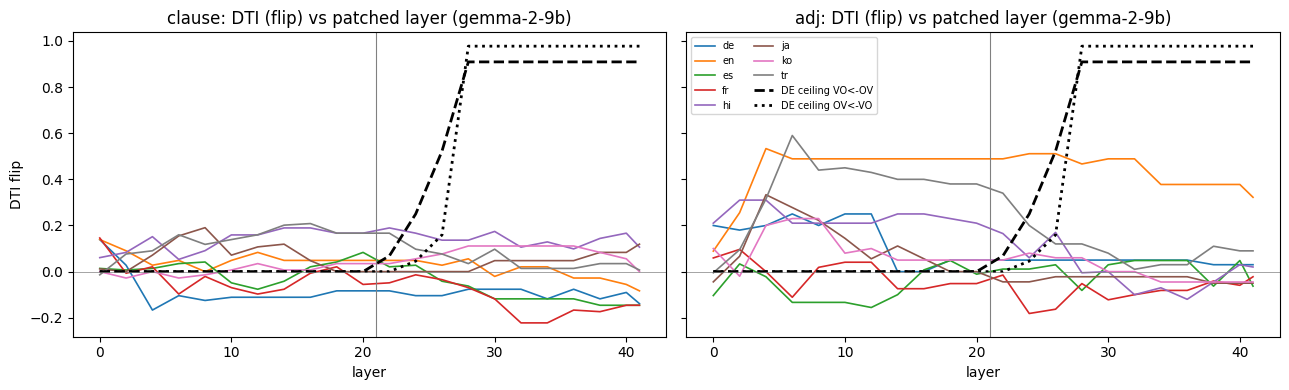

In [10]:
# ============================ PER-LAYER CURVES (exploratory; the pre-registered number is the late-window mean) ============================
def layer_curve(df, recips, metric="flip"):
    d = df[df.recip.isin(recips)]
    g = d.groupby(["recip", "scene", "kind", "layer"])[metric].mean().unstack("kind")
    if "opp" not in g.columns or "same" not in g.columns: return pd.Series(dtype=float)
    g["dti"] = g["opp"] - g["same"]
    return g["dti"].groupby("layer").mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, c in zip(axes, ("clause", "adj")):
    for r in sorted(DF[c].recip.unique()):
        s = layer_curve(DF[c], [r])
        if len(s): ax.plot(s.index, s.values, label=r, lw=1.2)
    for name, rc, ls in (("DE ceiling VO<-OV", ["V2a", "V2b"], "--"), ("DE ceiling OV<-VO", ["SUBa", "SUBb"], ":")):
        s = layer_curve(DF["de_frames"], rc)
        if len(s): ax.plot(s.index, s.values, "k", ls=ls, lw=2, label=name)
    ax.axvline(LATE0, color="grey", lw=0.8); ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"{c}: DTI (flip) vs patched layer ({MODEL_KEY})"); ax.set_xlabel("layer")
axes[0].set_ylabel("DTI flip"); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/{MODEL_KEY}_dti_layer_curves.png", dpi=140); plt.show()

In [11]:
# ============================ VERDICT (mechanical application of the frozen rule) ============================
P = PREREG
clean = REPDF[REPDF["class"].isin(["WALL", "TRANSFER", "AMBIGUOUS"])]
wall, transfer, amb = [clean[clean["class"] == k] for k in ("WALL", "TRANSFER", "AMBIGUOUS")]
if CEIL is None:
    verdict = "NO_CEILING: German in-language frames failed the clean gate; nothing cross-language can be claimed."
elif not CEIL["pass"]:
    verdict = (f"INSTRUMENT_INADEQUATE: in-language ceiling {CEIL['flip']:.2f} (need >= {P['ceil_min']}, each direction >= {P['ceil_dir_min']}). "
               "The patch cannot move the order preference even where it must; DTI ~ 0 across languages would be uninformative.")
elif len(transfer):
    verdict = "INVERSION_ABANDONED (word-order leg): TRANSFER in " + ", ".join(f"{r.constr}:{r.recip}" for r in transfer.itertuples())
elif len(wall) >= P["min_wall_cells"] and wall.constr.nunique() >= P["min_wall_constructions"]:
    verdict = f"WORD_ORDER_LEG_SUPPORTED: {len(wall)} clean WALL cells across {wall.constr.nunique()} constructions, ceiling passes, no TRANSFER."
else:
    verdict = f"INCONCLUSIVE: clean cells={len(clean)} (WALL {len(wall)}, AMBIGUOUS {len(amb)}, TRANSFER {len(transfer)}); rule needs >= {P['min_wall_cells']} WALL cells in >= {P['min_wall_constructions']} constructions."
print("="*100); print(MODEL_KEY, "->", verdict); print("="*100)
print(REPDF.groupby(["constr", "class"]).size().unstack(fill_value=0))
json.dump(dict(model=MODEL_KEY, verdict=verdict, ceiling=CEIL, prereg=PREREG, n_layers=NL, late0=LATE0,
               cells=REPDF[["constr","recip","dti_flip","lo","hi","loo_min","class"]].round(4).to_dict("records")),
          open(f"{RESULTS_DIR}/verdict_{MODEL_KEY}.json", "w"), indent=1, default=float)

gemma-2-9b -> INVERSION_ABANDONED (word-order leg): TRANSFER in adj:en
class   AMBIGUOUS  TRANSFER  UNUSABLE  WALL
constr                                     
adj             1         1         0     6
clause          3         0         1     4


In [12]:
# ============================ A4: scale comparison (after running 2b / 9b / 27b-it) ============================
rows = []
for f in sorted(glob.glob(f"{RESULTS_DIR}/verdict_*.json")):
    v = json.load(open(f))
    rows.append(dict(model=v["model"], ceiling_flip=(v["ceiling"] or {}).get("flip"), ceiling_pass=(v["ceiling"] or {}).get("pass"),
                     n_TRANSFER=sum(c["class"] == "TRANSFER" for c in v["cells"]), n_WALL=sum(c["class"] == "WALL" for c in v["cells"]),
                     n_AMBIG=sum(c["class"] == "AMBIGUOUS" for c in v["cells"]), verdict=v["verdict"].split(":")[0]))
print(pd.DataFrame(rows).to_string(index=False) if rows else "no verdict files yet")

     model  ceiling_flip  ceiling_pass  n_TRANSFER  n_WALL  n_AMBIG                              verdict
gemma-2-9b      0.733471          True           1      10        4 INVERSION_ABANDONED (word-order leg)
